# Phase 7: Better momentum signals, and why the risk forecasts were too low

Phase 6 left two open problems: the signals carry almost no information, and the risk model's tracking-error
forecasts were too low for the optimised portfolios (bias statistics 1.17–1.57). This notebook tests the two
standard improvements to momentum, then diagnoses the risk forecasts properly.

1. **Residual momentum** (Blitz, Huij & Martens 2011): momentum in the part of each stock's return the
   market does not explain, scaled by that part's volatility, so it measures how *consistently* a stock beat
   its beta. Blitz et al. use the three Fama-French factors; this data allows the market only (the cap-weighted
   point-in-time S&P 500, built from the dataset).
2. **Volatility-managed momentum** (Barroso & Santa-Clara 2015): hold less momentum when the momentum factor's
   own recent volatility is high, which is when it crashes. Target 12% a year, 6-month window, at most 2×,
   the paper's settings.
3. **The risk forecasts.** Phase 6 guessed that an equally weighted 3-year window reacts too slowly and
   suggested exponential weighting. That guess is tested here, along with the alternative: the problem
   is not the risk model but the alignment between the risk model and the alpha.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from mts import backtest as bt, baseline as BL, config as C, data, optimize as opt, risk, signals as S
from mts import plotting as plot
from mts.plotting import BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, LIGHT_BLUE, INK_2, SURFACE, AXIS, pct_axis

plot.apply_style()
C.RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)

def export(df, name):
    # Write a results table to results/<name>.csv so every number in the README can be traced
    df.to_csv(C.RESULTS_DIR / f"{name}.csv")
    return df

def fmt(df, pct=(), num=(), dec=2):
    return df.style.format("{:.1%}", subset=list(pct)).format(f"{{:.{dec}f}}", subset=list(num))

## 1. Residual momentum as a signal

At each month-end, each stock's last 36 monthly returns are regressed on the market's (at least 24 months
needed). Residual momentum = the sum of the residuals from 12 months to 1 month ago, divided by their
standard deviation. Same tests as Phase 5: rank IC with Newey-West t-statistics, three sub-periods,
quintile spreads, and Fama-MacBeth with the other signals as controls.

In [2]:
t0 = time.time()
panel = S.load_panel(residual_momentum=True)
top = panel[panel.rank_cap <= C.UNIVERSE_SIZE].copy()
corr = panel[["mom_12_1", "res_mom"]].groupby(level="date").corr(method="spearman").xs("res_mom", level=1)["mom_12_1"].mean()
print(f"Panel with residual momentum in {time.time() - t0:.0f}s; "
      f"coverage {panel.res_mom.notna().mean():.1%}; average rank correlation with 12-1 momentum {corr:.2f}")

HORIZONS = {"fwd_1m": 1, "fwd_3m": 3, "fwd_6m": 6, "fwd_12m": 12}
PERIODS = {"2003–2009": ("2002-12-31", "2009-12-31"), "2010–2016": ("2010-01-01", "2016-12-31"), "2017–2023": ("2017-01-01", "2023-12-31")}
rows = {}
for uname, uni in {"S&P 500": panel, "Top 50": top}.items():
    for s in ["mom_12_1", "res_mom"]:
        r = {}
        for h, lag in HORIZONS.items():
            m, t, _ = S.nw_mean(S.rank_ic(uni, s, h), max(lag - 1, 1))
            r[f"IC {h[4:]}"], r[f"t {h[4:]}"] = m, t
        ic3 = S.rank_ic(uni, s, "fwd_3m")
        for p, (a, b) in PERIODS.items():
            r[f"IC 3m {p}"] = S.nw_mean(ic3.loc[a:b], 2)[0]
        q = S.quintile_returns(uni, s, "fwd_1m")
        m, t, _ = S.nw_mean(q[5] - q[1], 1)
        r["Q5 − Q1 (annual)"], r["t Q5 − Q1"] = 12 * m, t
        rows[(uname, s)] = r
ic_p7 = export(pd.DataFrame(rows).T, "phase7_residual_momentum_ic")
fmt(ic_p7, pct=["Q5 − Q1 (annual)"], num=[c for c in ic_p7 if c != "Q5 − Q1 (annual)"], dec=3)

Panel with residual momentum in 0s; coverage 98.8%; average rank correlation with 12-1 momentum 0.71


In [3]:
FM = ["res_mom", "mom_12_1", "rev_1m", "vol_1y", "size", "book_to_price"]
fm_rows = {}
for uname, uni in {"S&P 500": panel, "Top 50": top}.items():
    fm = S.fama_macbeth(uni, FM, "fwd_1m")
    for s in FM[:2]:
        m, t, n = S.nw_mean(fm[s], 3)
        fm_rows[(uname, s)] = {"% per month per 1 sd": 100 * m, "t": t, "months": n}
fm_p7 = export(pd.DataFrame(fm_rows).T, "phase7_residual_momentum_fama_macbeth")
fm_p7.style.format({"% per month per 1 sd": "{:+.3f}", "t": "{:+.2f}", "months": "{:.0f}"})

## 2. Volatility-managed momentum

The momentum factor here is the classic top-minus-bottom quintile portfolio of the full S&P 500 (equally
weighted, rebalanced monthly, before costs). Each month its exposure is set to 12% ÷ its realised volatility
over the previous 126 trading days, at most 2×, using only past data.

In [4]:
t0 = time.time()
ls_daily = {s: S.long_short_daily(panel, s) for s in ["mom_12_1", "res_mom"]}
months = sorted(panel.index.get_level_values("date").unique())

def monthly(daily, scaled):
    ends = months[1:] + [daily.index[-1]]
    out = {}
    for a, b in zip(months, ends):
        r = (1 + daily.loc[a:b].iloc[1:]).prod() - 1
        k = S.vol_scale(daily, a) if scaled else 1.0
        if np.isfinite(k) and len(daily.loc[:a]) >= 126:
            out[b] = (r * k, k)
    return pd.DataFrame(out, index=["return", "exposure"]).T

def stats(r):
    cum = (1 + r).cumprod()
    m, t, _ = S.nw_mean(r, 1)
    return {"return (annual)": 12 * r.mean(), "volatility": np.sqrt(12) * r.std(), "Sharpe": np.sqrt(12) * r.mean() / r.std(),
            "t (mean)": t, "max drawdown": (cum / cum.cummax() - 1).min(), "worst month": r.min(), "skewness": r.skew(), "months": len(r)}

factor_rows, factor_curves = {}, {}
for s, label in [("mom_12_1", "12-1 momentum"), ("res_mom", "residual momentum")]:
    raw, scaled = monthly(ls_daily[s], False), monthly(ls_daily[s], True)
    common = raw.index.intersection(scaled.index)
    factor_rows[(label, "raw")] = stats(raw.loc[common, "return"])
    factor_rows[(label, "volatility-managed")] = {**stats(scaled.loc[common, "return"]), "average exposure": scaled.loc[common, "exposure"].mean()}
    factor_curves[(label, "raw")] = (1 + raw.loc[common, "return"]).cumprod()
    factor_curves[(label, "volatility-managed")] = (1 + scaled.loc[common, "return"]).cumprod()
    if s == "mom_12_1":
        exposure = scaled.loc[common, "exposure"]
factors = export(pd.DataFrame(factor_rows).T, "phase7_momentum_factor")
print(f"{time.time() - t0:.0f}s")
fmt(factors, pct=["return (annual)", "volatility", "max drawdown", "worst month"], num=["Sharpe", "t (mean)", "skewness", "average exposure"]).format("{:.0f}", subset=["months"])

1s


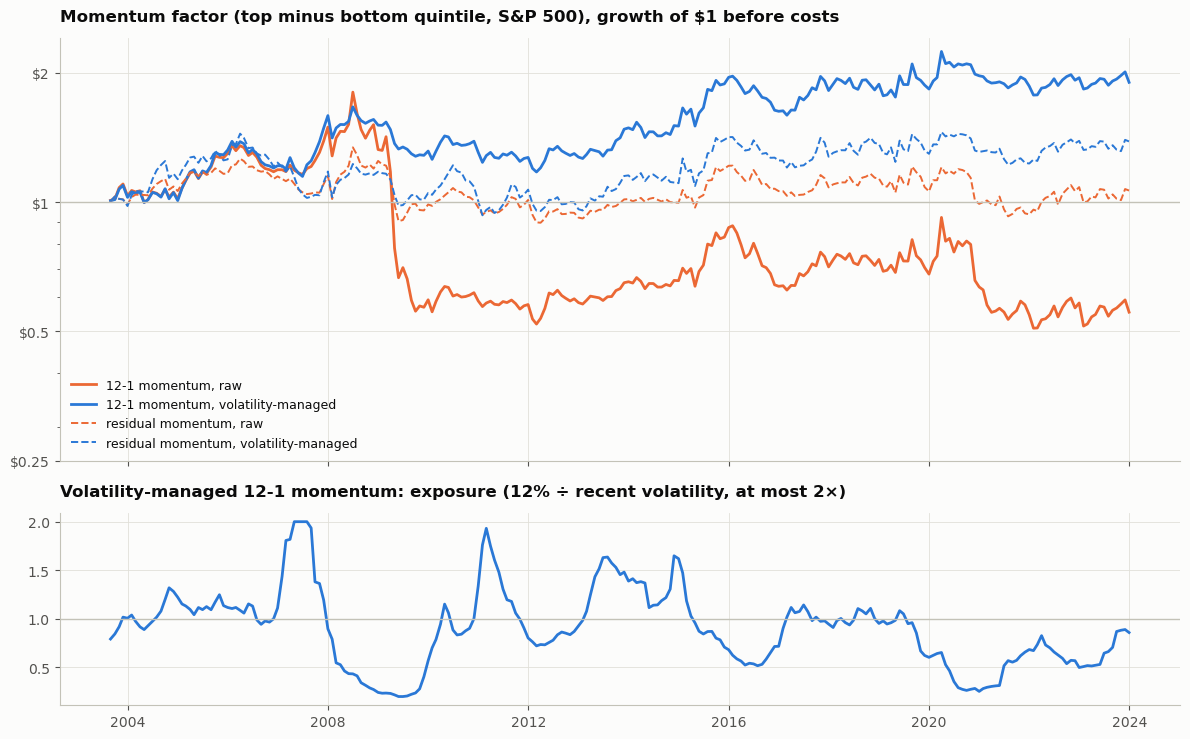

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for (label, kind), color, ls in [(("12-1 momentum", "raw"), ORANGE, "-"), (("12-1 momentum", "volatility-managed"), BLUE, "-"),
                                 (("residual momentum", "raw"), ORANGE, "--"), (("residual momentum", "volatility-managed"), BLUE, "--")]:
    c = factor_curves[(label, kind)]
    ax1.plot(c.index, c.values, color=color, ls=ls, lw=2 if label == "12-1 momentum" else 1.4, label=f"{label}, {kind}")
ax1.set_yscale("log")
ax1.set_yticks([0.25, 0.5, 1, 2])
ax1.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:g}"))
ax1.axhline(1, color=AXIS, lw=1)
ax1.set_title("Momentum factor (top minus bottom quintile, S&P 500), growth of $1 before costs")
ax1.legend(loc="lower left", fontsize=9)
ax2.plot(exposure.index, exposure.values, color=BLUE)
ax2.axhline(1, color=AXIS, lw=1)
ax2.set_title("Volatility-managed 12-1 momentum: exposure (12% ÷ recent volatility, at most 2×)")
plt.tight_layout()
plot.save(fig, "phase7_vol_managed_momentum")

## 3. In the portfolio

The new signals go through the Phase 6 optimiser unchanged (λ = 10, κ = 1, tracking error at most 4%, 10 bps
costs, active against the cap-weighted top 50). Volatility management scales the momentum alpha by the same
exposure as above. The last two rows are explained in section 4: the Phase 6 portfolios with the alpha added
to the risk model as a factor.

In [6]:
_models = {}
def model(f, half_life=None):
    key = (f, half_life)
    if key not in _models:
        u = data.universe(f)
        rets = data.daily_returns(f, u.index)
        _models[key] = (u, rets, risk.fit_pca(rets, C.N_FACTORS, half_life=half_life))
    return _models[key]

SIGS = ["hist_mean", "mom_12_1", "res_mom"]
IC_EST = {s: S.PointInTimeIC(S.rank_ic(top, s, "fwd_3m"), horizon_months=3, min_obs=24) for s in SIGS}

def active(sig, half_life=None, scale=False, aligned=False, diag=None):
    def weights(f):
        u, rets, rm = model(f, half_life)
        t = rm.tickers
        b = u[t] / u[t].sum()
        ic = IC_EST[sig](f)
        z = S.winsor_z(top.loc[f, sig].reindex(t).dropna())
        a = (2 * ic * rm.specific_vol * z).reindex(t).fillna(0) if np.isfinite(ic) else pd.Series(0.0, index=t)
        if scale:
            a = a * S.vol_scale(ls_daily["mom_12_1"], f)
        model_used = risk.add_alpha_factor(rm, rets, z, half_life) if aligned else rm
        current = bt.simulate.current
        w = opt.optimize_active(a, model_used.cov, b, current if len(current) else None, risk_aversion=10,
                                te_max=0.04, cost=C.COST_BPS / 1e4)
        if diag is not None:
            diag[f] = model_used.tracking_error(w - b)
            assert w.attrs["success"], f"optimiser failed on {f.date()}"
        return w
    return weights

DATES = data.period_ends("2010-01-01", "2023-12-31")
cap_top50 = lambda f: data.universe(f) / data.universe(f).sum()
cap_sp500 = lambda f: data.universe(f, 10_000) / data.universe(f, 10_000).sum()

def run(portfolios):
    diags = {name: {} for name in portfolios}
    sims = {name: bt.simulate(fn(diags[name]), DATES, "2023-12-31") for name, fn in portfolios.items()}
    curves = {k: v[0] for k, v in sims.items()}
    curves["Cap-weight top 50"] = bt.simulate(cap_top50, DATES, "2023-12-31")[0]
    curves["Cap-weight S&P 500"] = bt.simulate(cap_sp500, DATES, "2023-12-31")[0]
    perf = bt.performance(curves)[["Sharpe", "Turnover / yr", "Max drawdown"]].join(bt.active_stats(curves, "Cap-weight top 50"))
    bias = {k: bt.bias_statistic(curves[k], curves["Cap-weight top 50"], diags[k], DATES) for k in portfolios}
    perf["Forecast TE"] = pd.Series({k: np.mean(list(diags[k].values())) for k in portfolios})
    perf["Bias statistic"] = pd.Series({k: v["standardised"].std() for k, v in bias.items()})
    return perf, curves, bias

t0 = time.time()
PORTFOLIOS = {
    "Phase 6: historical mean": lambda d: active("hist_mean", diag=d),
    "Phase 6: momentum 12-1": lambda d: active("mom_12_1", diag=d),
    "Residual momentum": lambda d: active("res_mom", diag=d),
    "Momentum 12-1, volatility-managed": lambda d: active("mom_12_1", scale=True, diag=d),
    "Historical mean, alpha-aligned risk model": lambda d: active("hist_mean", aligned=True, diag=d),
    "Momentum 12-1, alpha-aligned risk model": lambda d: active("mom_12_1", aligned=True, diag=d),
}
perf_p7, curves_p7, bias_p7 = run(PORTFOLIOS)
export(perf_p7, "phase7_portfolios_2010_2023")
print(f"{time.time() - t0:.0f}s")
fmt(perf_p7, pct=["Turnover / yr", "Max drawdown", "Active return", "Tracking error", "Forecast TE"], num=["Sharpe", "IR", "t-stat", "Bias statistic"])

89s


,Sharpe,Turnover / yr,Max drawdown,Active return,Tracking error,IR,t-stat,Forecast TE,Bias statistic
Phase 6: historical mean,0.54,28.3%,-31.3%,0.3%,1.6%,0.16,0.61,1.2%,1.17
Phase 6: momentum 12-1,0.54,25.0%,-29.5%,0.1%,0.8%,0.09,0.34,0.6%,1.57
Residual momentum,0.53,91.7%,-30.5%,-0.0%,1.5%,-0.02,-0.06,1.2%,1.11
"Momentum 12-1, volatility-managed",0.53,22.8%,-29.5%,0.0%,0.8%,0.00,0.01,0.5%,1.47
"Historical mean, alpha-aligned risk model",0.54,23.0%,-31.1%,0.3%,1.3%,0.21,0.78,1.1%,1.10
"Momentum 12-1, alpha-aligned risk model",0.53,21.8%,-29.5%,0.0%,0.7%,0.04,0.15,0.5%,1.52
Cap-weight top 50,0.53,21.9%,-30.0%,0.0%,0.0%,nan,nan,nan%,nan
Cap-weight S&P 500,0.52,7.9%,-33.6%,-0.5%,3.6%,-0.14,-0.51,nan%,nan


## 4. Why were the risk forecasts too low?

The bias statistic of an accurate model lies between about 0.81 and 1.19 for 56 quarters. Phase 6's
optimised portfolios came out at 1.17–1.57. Three tests, in turn.

**(a) Exponential weighting** (Phase 6's suggested fix): the same portfolios with risk models whose
covariance halves its weight on a day every 126, 63 or 42 trading days.

In [7]:
t0 = time.time()
HL = {f"half-life {hl} days": hl for hl in (126, 63, 42)}
ewma_ports = {}
for label, hl in HL.items():
    ewma_ports[f"historical mean, {label}"] = (lambda h: lambda d: active("hist_mean", half_life=h, diag=d))(hl)
    ewma_ports[f"momentum 12-1, {label}"] = (lambda h: lambda d: active("mom_12_1", half_life=h, diag=d))(hl)
perf_ewma, _, _ = run(ewma_ports)
ewma_table = pd.concat([perf_p7.loc[["Phase 6: historical mean", "Phase 6: momentum 12-1"]].rename(
    index={"Phase 6: historical mean": "historical mean, equal weights", "Phase 6: momentum 12-1": "momentum 12-1, equal weights"}),
    perf_ewma.drop(index=["Cap-weight top 50", "Cap-weight S&P 500"])])
ewma_table = export(ewma_table[["Bias statistic", "Forecast TE", "Tracking error", "Active return", "IR", "Turnover / yr"]].sort_index(), "phase7_ewma_bias")
print(f"{time.time() - t0:.0f}s")
fmt(ewma_table, pct=["Forecast TE", "Tracking error", "Active return", "Turnover / yr"], num=["Bias statistic", "IR"])

95s


,Bias statistic,Forecast TE,Tracking error,Active return,IR,Turnover / yr
"historical mean, equal weights",1.17,1.2%,1.6%,0.3%,0.16,28.3%
"historical mean, half-life 126 days",1.20,1.2%,1.6%,0.4%,0.25,29.0%
"historical mean, half-life 42 days",1.34,1.2%,1.7%,0.4%,0.23,36.7%
"historical mean, half-life 63 days",1.26,1.2%,1.6%,0.4%,0.25,32.4%
"momentum 12-1, equal weights",1.57,0.6%,0.8%,0.1%,0.09,25.0%
"momentum 12-1, half-life 126 days",1.55,0.5%,0.8%,-0.0%,-0.03,24.0%
"momentum 12-1, half-life 42 days",1.57,0.5%,0.8%,-0.1%,-0.08,23.3%
"momentum 12-1, half-life 63 days",1.59,0.5%,0.8%,-0.1%,-0.14,23.3%


**(b) Is the risk model itself wrong?** Two checks that do not involve the optimiser, every quarter
2010–2023:

* **Random active portfolios:** 200 random long-short tilts of the top 50 a quarter (11,200 in all). Each
  one's realised return is divided by the model's forecast for it.
* **Specific risk:** each stock's realised quarterly return after removing the model's factors, divided by
  its forecast specific volatility (about 2,800 stock-quarters).

If the model is accurate, both give about 1.

In [8]:
t0 = time.time()
rng = np.random.default_rng(0)
P = data.prices()
ends = DATES[1:] + [P.index[-1]]
fits = {"Statistical, equal weights": lambda r: risk.fit_pca(r, C.N_FACTORS),
        "Statistical, half-life 63 days": lambda r: risk.fit_pca(r, C.N_FACTORS, half_life=63),
        "Ledoit-Wolf sample covariance": None}
checks = {}
for label, fit in fits.items():
    z_rand, z_spec = [], []
    for f, g in zip(DATES, ends):
        u = data.universe(f)
        rets = data.daily_returns(f, u.index)
        t = list(rets.columns)
        h = (g - f).days / 365.25
        p = P.loc[f:g, t].ffill()
        rq = (p.iloc[-1] / p.iloc[0] - 1).fillna(0).values
        if fit is None:
            Sigma = BL.covariance(rets, "ledoit_wolf")
        else:
            rm = fit(rets)
            Sigma = rm.cov
            daily = P.loc[f:g, t].pct_change(fill_method=None).iloc[1:].fillna(0).values
            resid = (daily - (daily @ rm.B) @ rm.B.T).sum(axis=0)
            z_spec += list(resid / (rm.specific_vol.values * np.sqrt(h)))
        A = rng.normal(size=(200, len(t)))
        A -= A.mean(axis=1, keepdims=True)
        te = np.sqrt(np.einsum("ij,jk,ik->i", A, Sigma, A))
        z_rand += list(A @ rq / (te * np.sqrt(h)))
    checks[label] = {"random active portfolios": np.std(z_rand), "n portfolios": len(z_rand),
                     "specific risk": np.std(z_spec) if z_spec else np.nan, "n stock-quarters": len(z_spec)}
checks = export(pd.DataFrame(checks).T, "phase7_risk_model_checks")
print(f"{time.time() - t0:.0f}s")
checks.style.format({"random active portfolios": "{:.2f}", "specific risk": "{:.2f}", "n portfolios": "{:,.0f}", "n stock-quarters": "{:,.0f}"}, na_rep="—")

9s


,random active portfolios,n portfolios,specific risk,n stock-quarters
"Statistical, equal weights",0.98,"11,200",0.98,"2,769"
"Statistical, half-life 63 days",1.06,"11,200",1.11,"2,769"
Ledoit-Wolf sample covariance,0.96,"11,200",—,0


**(c) Alpha–risk alignment.** If the model is right for portfolios in general but wrong for the optimised
ones, the optimiser is finding directions where the model understates risk. The obvious one is the alpha
itself: the model has no factor for it, so it treats a bet along the alpha as diversifiable stock-specific
risk, even though stocks with similar scores tend to move together (momentum winners did in 2009). The
standard remedy (Lee & Stefek 2008; Ceria, Saxena & Stubbs 2012) adds the signal to the risk model as one more
factor, with its variance measured from past returns along the signal (`risk.add_alpha_factor`). Those are the
last two rows of the section 3 table.

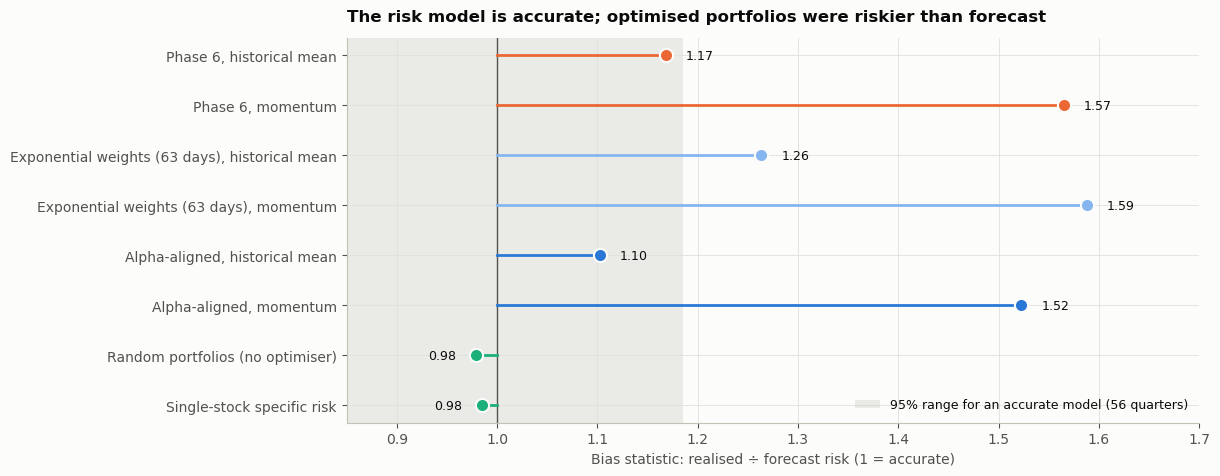

In [9]:
bias_rows = {
    "Phase 6, historical mean": perf_p7.loc["Phase 6: historical mean", "Bias statistic"],
    "Phase 6, momentum": perf_p7.loc["Phase 6: momentum 12-1", "Bias statistic"],
    "Exponential weights (63 days), historical mean": perf_ewma.loc["historical mean, half-life 63 days", "Bias statistic"],
    "Exponential weights (63 days), momentum": perf_ewma.loc["momentum 12-1, half-life 63 days", "Bias statistic"],
    "Alpha-aligned, historical mean": perf_p7.loc["Historical mean, alpha-aligned risk model", "Bias statistic"],
    "Alpha-aligned, momentum": perf_p7.loc["Momentum 12-1, alpha-aligned risk model", "Bias statistic"],
    "Random portfolios (no optimiser)": checks.loc["Statistical, equal weights", "random active portfolios"],
    "Single-stock specific risk": checks.loc["Statistical, equal weights", "specific risk"],
}
band = 1.96 * np.sqrt(1 / (2 * len(DATES)))
fig, ax = plt.subplots(figsize=(11, 5))
names = list(bias_rows)[::-1]
vals = [bias_rows[n] for n in names]
colors = [AQUA if "Random" in n or "Single" in n else (BLUE if "aligned" in n else (LIGHT_BLUE if "Exponential" in n else ORANGE)) for n in names]
ax.axvspan(1 - band, 1 + band, color=AXIS, alpha=0.3, lw=0, zorder=0, label=f"95% range for an accurate model ({len(DATES)} quarters)")
ax.axvline(1, color=INK_2, lw=1, zorder=1)
for i, (v, c) in enumerate(zip(vals, colors)):
    ax.plot([1, v], [i, i], color=c, lw=2, zorder=2)
    ax.scatter(v, i, s=90, color=c, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.text(v + (0.02 if v >= 1 else -0.02), i, f"{v:.2f}", va="center", ha="left" if v >= 1 else "right", fontsize=9)
ax.set_yticks(range(len(names)), names)
ax.set_xlim(0.85, 1.7)
ax.set_xlabel("Bias statistic: realised ÷ forecast risk (1 = accurate)")
ax.set_title("The risk model is accurate; optimised portfolios were riskier than forecast")
ax.legend(loc="lower right", fontsize=9)
plot.save(fig, "phase7_bias")

**Which quarters drive momentum's bias?** The bias statistic is a standard deviation, so a few large
surprises can dominate it. The largest standardised active returns of the momentum portfolios:

In [10]:
rows = []
for name in ["Phase 6: momentum 12-1", "Momentum 12-1, alpha-aligned risk model", "Phase 6: historical mean"]:
    b = bias_p7[name]
    for d in b["standardised"].abs().nlargest(4).index:
        rows.append({"portfolio": name, "quarter from": d.date(), "realised active return": b.loc[d, "realised active return"],
                     "forecast TE (quarter)": b.loc[d, "forecast TE (period)"], "standardised": b.loc[d, "standardised"]})
    without = b["standardised"].drop(b["standardised"].abs().nlargest(2).index).std()
    rows.append({"portfolio": name, "quarter from": "bias without the 2 largest", "standardised": without})
surprises = export(pd.DataFrame(rows).set_index(["portfolio", "quarter from"]), "phase7_largest_surprises")
surprises.style.format({"realised active return": "{:+.2%}", "forecast TE (quarter)": "{:.2%}", "standardised": "{:+.2f}"}, na_rep="")

## 5. Findings

**1. Residual momentum is steadier than raw momentum, but still not significant.** In the top 50 its 3-month
IC is positive in all three sub-periods (0.030, 0.014, 0.019) where 12-1 momentum's is not (−0.011, −0.001,
0.072); its quintile spread is +4.6% a year (t 1.62). In the full S&P 500 it has no premium (IC 0.001,
t 0.11). With 12-1 momentum and the other signals as controls (Fama-MacBeth) it adds nothing (t −0.71 to −0.73):
the two are correlated 0.71.

**2. Volatility management transforms the momentum factor's risk.** For the S&P 500 top-minus-bottom momentum
quintile (245 months, before costs), it turns −1.0% a year into +4.0% (Sharpe −0.05 to 0.31, t 1.50), the
maximum drawdown from −71.8% to −29.5%, the worst month from −33.6% to −11.3%, and the skewness from −0.89 to
+0.45, with an average exposure of 0.90. This reproduces Barroso & Santa-Clara's result with their settings;
the higher return is still not statistically significant. Residual momentum barely crashes in the first place
(maximum drawdown −33.2%) and gains less from it (Sharpe 0.09 to 0.19).

**3. Neither improvement helps the long-only top-50 portfolio.** Through the Phase 6 optimiser, residual
momentum earns −0.0% a year against the cap-weighted top 50 with 92% turnover, and volatility-managed momentum
0.0%. The momentum alpha in the top 50 is so small (Phase 5: IC 0.003) that scaling it changes nothing.

**4. Phase 6's explanation of the risk forecasts was wrong.** Phase 6 suggested that an equally weighted
3-year window reacts too slowly and that exponential weighting would fix it. It does not: bias statistics get
slightly worse as the half-life shortens (historical mean 1.17 → 1.20, 1.26, 1.34 for 126, 63, 42 days;
momentum 1.55–1.59).

**5. The risk model is accurate; the optimised portfolios were misaligned with it.** For 11,200 random active
portfolios the bias statistic is 0.98, and for 2,769 stock-quarters of specific risk 0.98. The model is wrong
only for portfolios the optimiser builds from the alpha. Adding the alpha to the risk model as a factor brings
the historical mean's bias from 1.17 to 1.10, within the 0.81–1.19 range of an accurate model, cuts its
turnover from 28% to 23% a year and raises its IR from 0.16 to 0.21 (t 0.78).

**6. Momentum's risk is mis-forecast because of rare extreme quarters.** Alignment only moves momentum from
1.57 to 1.52. Two quarters dominate: Q3 2020 (+1.8% active against a 0.35% forecast, +5.3 standard deviations,
the post-COVID technology rally) and Q3 2015 (−4.9). Without the two largest surprises the bias is 1.25 for
momentum and 1.01 for the historical mean. Momentum's active returns have fat tails that no variance forecast
captures, the same crash risk that volatility management addresses for the factor.

**Answer.** The better momentum signals improve the momentum *factor* (volatility management most of all) but
not the long-only top-50 strategy, where momentum has no information to scale. The risk model was never the
problem: aligning it with the alpha fixes the risk forecasts for the historical-mean strategy, and momentum's
remaining error comes from a few extreme quarters.

**Limitations**
* Residual momentum uses the market only; Blitz et al. also remove size and value (Fama-French factors are not in the data).
* The momentum factor is long-short and before costs; the portfolio tests are long-only and after costs.
* As before: price returns, constant 3% risk-free rate, linear costs, 56 quarters for each bias statistic.
